# Projeto Final — Análise de Dados do Campeonato Brasileiro Série A (2003–2024)

**Autor:** Thiago Paiano · **Curso:** Analista de Dados (EBAC)

## Problema de negócio

O "fator casa" é tratado como verdade no futebol brasileiro: jogar no próprio estádio, com a torcida, daria uma vantagem grande.
Este projeto usa 22 temporadas de dados públicos do Brasileirão para responder:

1. **A vantagem de jogar em casa existe e está mudando ao longo do tempo?**
2. **O que aconteceu em 2020, a temporada inteira disputada sem público?**
3. **Quais estatísticas de jogo (chutes, posse, passes) mais se relacionam com gols e vitória?**
4. **Quando os gols e os cartões acontecem dentro da partida?**

## Estrutura do notebook

| Fase | Seção |
|---|---|
| 1. Seleção dos dados | Fonte, tabelas e checagem dos requisitos |
| 2. Análise exploratória — diagnóstico | Estrutura, valores ausentes e inconsistências dos dados brutos |
| 3. Tratamento e preparação | Limpeza, padronização e colunas derivadas |
| 2. Análise exploratória — padrões | 8 análises (distribuição, média/mediana, tendência, outliers, correlação, dispersão...) |
| 4. Visualização | 6 visualizações finais + exportação para o dashboard no Looker Studio |

> A análise exploratória foi dividida em duas partes: o **diagnóstico** vem antes do tratamento (para descobrir o que precisa ser limpo)
> e a **busca de padrões** vem depois (para que as conclusões sejam tiradas de dados confiáveis).

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ---------- Identidade visual dos gráficos ----------
AZUL, LARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"   # séries categóricas (ordem fixa)
CINZA = "#8f8e8a"                                         # elementos de contexto
TEXTO, TEXTO_2 = "#0b0b0b", "#52514e"
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.figsize": (11, 5), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d9d8d4", "axes.labelcolor": TEXTO_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "text.color": TEXTO,
    "lines.linewidth": 2, "legend.frameon": False,
})

def subtitulo(ax, texto):
    """Escreve um subtítulo explicativo logo abaixo do título do gráfico."""
    ax.text(0, 1.02, texto, transform=ax.transAxes, fontsize=10, color=TEXTO_2, va="bottom")

---
# Fase 1 — Seleção dos dados

**Fonte:** [Brasileirão Dataset — adaoduque/Brasileirao_Dataset (GitHub)](https://github.com/adaoduque/Brasileirao_Dataset), base pública
com todas as partidas da Série A de 2003 a 2024, também publicada no Kaggle e usada em diversos trabalhos acadêmicos sobre o campeonato.

| Tabela | Arquivo | Conteúdo |
|---|---|---|
| `partidas` | `campeonato-brasileiro-full.csv` | 1 linha por partida: data, hora, mandante, visitante, placar, arena, técnicos, formações |
| `estatisticas` | `campeonato-brasileiro-estatisticas-full.csv` | 1 linha por clube por partida: chutes, posse, passes, faltas, cartões, escanteios |
| `gols` | `campeonato-brasileiro-gols.csv` | 1 linha por gol: clube, atleta, minuto, tipo (pênalti, contra) |
| `cartoes` | `campeonato-brasileiro-cartoes.csv` | 1 linha por cartão: clube, atleta, posição, minuto, cor |

**Chave de cruzamento:** `partidas.ID` = `partida_id` nas outras três tabelas.

In [2]:
# Lê os arquivos da pasta local "dados_brutos"; se não existirem, baixa direto do repositório público.
URL_BASE = "https://raw.githubusercontent.com/adaoduque/Brasileirao_Dataset/master/"
PASTA = Path("dados_brutos")
ARQUIVOS = {
    "partidas": "campeonato-brasileiro-full.csv",
    "estatisticas": "campeonato-brasileiro-estatisticas-full.csv",
    "gols": "campeonato-brasileiro-gols.csv",
    "cartoes": "campeonato-brasileiro-cartoes.csv",
}

def ler(nome):
    local = PASTA / ARQUIVOS[nome]
    return pd.read_csv(local if local.exists() else URL_BASE + ARQUIVOS[nome])

partidas_raw = ler("partidas")
estat_raw = ler("estatisticas")
gols_raw = ler("gols")
cartoes_raw = ler("cartoes")

In [3]:
# Checagem dos requisitos mínimos do projeto
tabelas = {"partidas": partidas_raw, "estatisticas": estat_raw, "gols": gols_raw, "cartoes": cartoes_raw}
requisitos = pd.DataFrame({
    "linhas": {k: len(v) for k, v in tabelas.items()},
    "colunas": {k: v.shape[1] for k, v in tabelas.items()},
    "tem_data": {"partidas": True, "estatisticas": False, "gols": False, "cartoes": False},
})
requisitos["mais_de_5_colunas"] = requisitos.colunas > 5
requisitos["mais_de_100_linhas"] = requisitos.linhas > 100
requisitos

,linhas,colunas,tem_data,mais_de_5_colunas,mais_de_100_linhas
partidas,8785,16,True,True,True
estatisticas,17570,13,False,True,True
gols,9861,6,False,True,True
cartoes,20953,8,False,True,True


In [4]:
print("✔ Pelo menos 3 tabelas para cruzamento:", len(tabelas) >= 3)
print("✔ Pelo menos 1 tabela com data:        ", requisitos.tem_data.any())
print("✔ Pelo menos 2 tabelas com > 5 colunas:", requisitos.mais_de_5_colunas.sum() >= 2)
print("✔ Pelo menos 2 tabelas com > 100 linhas:", requisitos.mais_de_100_linhas.sum() >= 2)

✔ Pelo menos 3 tabelas para cruzamento: True
✔ Pelo menos 1 tabela com data:         True
✔ Pelo menos 2 tabelas com > 5 colunas: True
✔ Pelo menos 2 tabelas com > 100 linhas: True


---
# Fase 2 (parte A) — Análise exploratória: diagnóstico dos dados brutos

In [5]:
for nome, df in tabelas.items():
    print(f"\n=== {nome.upper()} — {df.shape[0]:,} linhas × {df.shape[1]} colunas")
    print(df.dtypes.to_string())


=== PARTIDAS — 8,785 linhas × 16 colunas
ID                    int64
rodata                int64
data                    str
hora                    str
mandante                str
visitante               str
formacao_mandante       str
formacao_visitante      str
tecnico_mandante        str
tecnico_visitante       str
vencedor                str
arena                   str
mandante_Placar       int64
visitante_Placar      int64
mandante_Estado         str
visitante_Estado        str

=== ESTATISTICAS — 17,570 linhas × 13 colunas
partida_id         int64
rodata             int64
clube                str
chutes             int64
chutes_no_alvo     int64
posse_de_bola        str
passes             int64
precisao_passes      str
faltas             int64
cartao_amarelo     int64
cartao_vermelho    int64
impedimentos       int64
escanteios         int64

=== GOLS — 9,861 linhas × 6 colunas
partida_id     int64
rodata         int64
clube            str
atleta           str
minuto           

In [6]:
partidas_raw.head()

,ID,rodata,data,hora,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,vencedor,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado
0,1,1,29/03/2003,16:00,Guarani,Vasco,NaN,NaN,NaN,NaN,Guarani,Brinco de Ouro,4,2,SP,RJ
1,2,1,29/03/2003,16:00,Athletico-PR,Gremio,NaN,NaN,NaN,NaN,Athletico-PR,Arena da Baixada,2,0,PR,RS
2,3,1,30/03/2003,16:00,Flamengo,Coritiba,NaN,NaN,NaN,NaN,-,Maracanã,1,1,RJ,PR
3,4,1,30/03/2003,16:00,Goias,Paysandu,NaN,NaN,NaN,NaN,-,Serra Dourada,2,2,GO,PA
4,5,1,30/03/2003,16:00,Internacional,Ponte Preta,NaN,NaN,NaN,NaN,-,Beira Rio,1,1,RS,SP


In [7]:
# Valores ausentes por tabela (%)
ausentes = pd.concat(
    {nome: (df.isna().mean() * 100).round(1) for nome, df in tabelas.items()}, axis=0
).rename("% ausente").to_frame()
ausentes[ausentes["% ausente"] > 0]

% ausente
partidas     formacao_mandante       56.60
             formacao_visitante      56.60
             tecnico_mandante        52.50
             tecnico_visitante       52.50
estatisticas posse_de_bola           61.20
             precisao_passes         74.30
gols         tipo_de_gol             88.00
cartoes      num_camisa               1.80
             posicao                  5.70

In [8]:
# Linhas duplicadas
{nome: int(df.duplicated().sum()) for nome, df in tabelas.items()}

{'partidas': 0, 'estatisticas': 0, 'gols': 0, 'cartoes': 0}

In [9]:
# Quantidade de partidas por ANO CIVIL — repare em 2020 e 2021
anos = pd.to_datetime(partidas_raw["data"], dayfirst=True).dt.year
anos.value_counts().sort_index().to_frame("partidas").T

data,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
partidas,552,552,462,380,380,380,380,380,380,380,380,380,380,379,380,380,380,268,492,380,380,380


**2020 tem 268 partidas e 2021 tem 492.** A temporada 2020 foi interrompida pela pandemia e só terminou em fevereiro de 2021.
Usar o ano civil como "temporada" misturaria dois campeonatos — será preciso criar uma coluna `temporada`.

In [10]:
# Estatísticas de jogo: os zeros são reais ou dados não coletados?
tmp = estat_raw.merge(partidas_raw[["ID", "data"]], left_on="partida_id", right_on="ID")
tmp["ano"] = pd.to_datetime(tmp["data"], dayfirst=True).dt.year
cobertura = tmp.assign(sem_dados=(tmp.chutes == 0) & (tmp.passes == 0) & (tmp.faltas == 0)) \
               .groupby("ano")["sem_dados"].mean().mul(100).round(0)
cobertura.to_frame("% linhas com chutes, passes e faltas = 0").T

ano,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
"% linhas com chutes, passes e faltas = 0",100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,96.00,0.00,0.00,0.00,0.00,6.00,0.00,0.00,0.00,0.00,100.00


Até 2014 e em 2024 praticamente todas as linhas têm **chutes, passes e faltas iguais a zero** — é impossível uma partida sem nenhum chute
e nenhuma falta. Esses zeros significam **"não coletado"** e precisam virar valores ausentes, senão puxariam todas as médias para baixo.

In [11]:
# Colunas de percentual armazenadas como texto
estat_raw[["posse_de_bola", "precisao_passes"]].dropna().head()

,posse_de_bola,precisao_passes
12250,60%,86%
12251,40%,81%
12252,66%,88%
12253,34%,72%
12254,46%,85%


In [12]:
# Minutos dos gols e cartões: texto com acréscimos ("90+3")
print(sorted(gols_raw["minuto"].astype(str).unique(), key=lambda m: eval(m))[-15:])

['89', '90', '90+1', '90+2', '90+3', '90+4', '90+5', '90+6', '90+7', '90+8', '90+9', '90+10', '90+11', '90+12', '90+13']


In [13]:
# Categorias inconsistentes
print("Posições:", cartoes_raw["posicao"].value_counts(dropna=False).to_dict())
print("Tipos de gol:", gols_raw["tipo_de_gol"].value_counts(dropna=False).to_dict())
print("Arenas com espaço no início:", partidas_raw["arena"].str.startswith(" ").sum())
print("Arenas com marcação '(PF)':", partidas_raw["arena"].str.contains("PF", regex=False).sum())

Posições: {'Meio-campo': 8697, 'Zagueiro': 7460, 'Atacante': 2874, nan: 1198, 'Goleiro': 702, 'Zagueira': 22}
Tipos de gol: {nan: 8678, 'Penalty': 935, 'Gol Contra': 248}
Arenas com espaço no início: 0
Arenas com marcação '(PF)': 25


In [14]:
# O campo "vencedor" bate com o placar?
p = partidas_raw
placar_res = np.select([p.mandante_Placar > p.visitante_Placar, p.mandante_Placar < p.visitante_Placar],
                       [p.mandante, p.visitante], default="-")
p.loc[placar_res != p.vencedor, ["ID", "data", "mandante", "visitante", "mandante_Placar", "visitante_Placar", "vencedor"]]

,ID,data,mandante,visitante,mandante_Placar,visitante_Placar,vencedor
1113,1114,24/04/2005,Brasiliense,Vasco,0,1,-


In [15]:
# Os gols da tabela "gols" batem com os placares? (tabela de gols existe a partir da partida 4607, em 2014)
gols_por_partida = gols_raw.groupby("partida_id").size()
placar_total = partidas_raw.set_index("ID").eval("mandante_Placar + visitante_Placar")
placar_2014 = placar_total[placar_total.index >= gols_raw.partida_id.min()]
divergentes = (gols_por_partida.reindex(placar_2014.index, fill_value=0) != placar_2014).sum()
print(f"Partidas desde 2014: {len(placar_2014):,} | gols no placar: {placar_2014.sum():,} | "
      f"gols na tabela: {len(gols_raw):,} | partidas divergentes: {divergentes}")

Partidas desde 2014: 4,179 | gols no placar: 9,861 | gols na tabela: 9,861 | partidas divergentes: 0


### Resumo do diagnóstico

| Problema | Tabela | Tratamento |
|---|---|---|
| Temporada 2020 terminou em 2021 | partidas | criar `temporada` |
| Datas como texto (`dd/mm/aaaa`) | partidas | converter para `datetime` |
| Coluna com erro de digitação (`rodata`) e nomes mistos (`mandante_Placar`) | todas | padronizar para `snake_case` |
| 1 partida com `vencedor` diferente do placar (ID 1114) | partidas | recalcular o resultado a partir do placar |
| Técnicos e formações ausentes nos anos antigos (~52–57%) | partidas | preencher com "Não informado" |
| Espaços e marcação `(PF)` no nome da arena | partidas | limpar o texto e guardar a marcação numa coluna |
| Zeros que significam "não coletado" | estatisticas | converter para ausente e marcar `stats_disponivel` |
| Percentuais como texto (`"35%"`) | estatisticas | converter para número |
| Minutos como texto com acréscimo (`"90+3"`) | gols, cartoes | converter para número + coluna de acréscimo |
| Categoria com grafia diferente (`Zagueira`) e posições vazias | cartoes | padronizar |
| `tipo_de_gol` vazio = gol comum | gols | preencher com "Normal" |

Pontos positivos: **nenhuma linha duplicada**, chaves de cruzamento 100% consistentes, e a tabela de gols bate exatamente com os placares.

---
# Fase 3 — Tratamento e preparação dos dados

### 3.1 Partidas

In [16]:
partidas = partidas_raw.rename(columns={
    "ID": "partida_id", "rodata": "rodada", "mandante_Placar": "mandante_placar",
    "visitante_Placar": "visitante_placar", "mandante_Estado": "mandante_estado",
    "visitante_Estado": "visitante_estado",
}).copy()

# Datas e horários padronizados
partidas["data"] = pd.to_datetime(partidas["data"], format="%d/%m/%Y")
partidas["hora_inicio"] = pd.to_datetime(partidas["hora"], format="%H:%M").dt.hour
partidas = partidas.drop(columns="hora")

# COLUNA DERIVADA 1 — temporada: jogos de jan–mar/2021 pertencem à temporada 2020
partidas["temporada"] = np.where(
    (partidas.data.dt.year == 2021) & (partidas.data.dt.month <= 3), 2020, partidas.data.dt.year
)

# COLUNA DERIVADA 2 — resultado calculado pelo placar (corrige a partida 1114)
partidas["resultado"] = np.select(
    [partidas.mandante_placar > partidas.visitante_placar, partidas.mandante_placar < partidas.visitante_placar],
    ["Vitória mandante", "Vitória visitante"], default="Empate",
)
partidas["vencedor"] = np.select(
    [partidas.resultado == "Vitória mandante", partidas.resultado == "Vitória visitante"],
    [partidas.mandante, partidas.visitante], default="Empate",
)

# COLUNAS DERIVADAS 3 a 6 — gols, saldo e pontos
partidas["total_gols"] = partidas.mandante_placar + partidas.visitante_placar
partidas["saldo_mandante"] = partidas.mandante_placar - partidas.visitante_placar
partidas["pontos_mandante"] = partidas.resultado.map({"Vitória mandante": 3, "Empate": 1, "Vitória visitante": 0})
partidas["pontos_visitante"] = partidas.resultado.map({"Vitória mandante": 0, "Empate": 1, "Vitória visitante": 3})

# COLUNAS DERIVADAS 7 a 9 — calendário e contexto
DIAS = {0: "Segunda", 1: "Terça", 2: "Quarta", 3: "Quinta", 4: "Sexta", 5: "Sábado", 6: "Domingo"}
partidas["dia_semana"] = partidas.data.dt.dayofweek.map(DIAS)
max_rodada = partidas.groupby("temporada").rodada.transform("max")
partidas["turno"] = np.where(partidas.rodada <= max_rodada / 2, "1º turno", "2º turno")
partidas["publico"] = np.where(partidas.temporada == 2020, "Sem público (2020)", "Com público")

# Texto padronizado
partidas["arena_portoes_fechados"] = partidas.arena.str.contains("PF", regex=False)  # marcação original "(PF)"
partidas["arena"] = (partidas.arena.str.replace(r"\s*\(?\*\s*\(?PF\)?", "", regex=True)
                                   .str.replace(r"\s+", " ", regex=True).str.strip())
for col in ["formacao_mandante", "formacao_visitante", "tecnico_mandante", "tecnico_visitante"]:
    partidas[col] = partidas[col].fillna("Não informado").str.strip()

# Código ISO dos estados (o Looker Studio usa para desenhar o mapa)
partidas["mandante_estado_iso"] = "BR-" + partidas.mandante_estado
partidas["visitante_estado_iso"] = "BR-" + partidas.visitante_estado

partidas.head(3)

,partida_id,rodada,data,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,vencedor,arena,mandante_placar,visitante_placar,mandante_estado,visitante_estado,hora_inicio,temporada,resultado,total_gols,saldo_mandante,pontos_mandante,pontos_visitante,dia_semana,turno,publico,arena_portoes_fechados,mandante_estado_iso,visitante_estado_iso
0,1,1,2003-03-29,Guarani,Vasco,Não informado,Não informado,Não informado,Não informado,Guarani,Brinco de Ouro,4,2,SP,RJ,16,2003,Vitória mandante,6,2,3,0,Sábado,1º turno,Com público,False,BR-SP,BR-RJ
1,2,1,2003-03-29,Athletico-PR,Gremio,Não informado,Não informado,Não informado,Não informado,Athletico-PR,Arena da Baixada,2,0,PR,RS,16,2003,Vitória mandante,2,2,3,0,Sábado,1º turno,Com público,False,BR-PR,BR-RS
2,3,1,2003-03-30,Flamengo,Coritiba,Não informado,Não informado,Não informado,Não informado,Empate,Maracanã,1,1,RJ,PR,16,2003,Empate,2,0,1,1,Domingo,1º turno,Com público,False,BR-RJ,BR-PR


In [17]:
# Conferências do tratamento
print("Partidas por temporada (todas devem fechar o campeonato):")
print(partidas.temporada.value_counts().sort_index().to_dict())
print("\nPartida 1114 corrigida:")
print(partidas.loc[partidas.partida_id == 1114, ["mandante", "visitante", "mandante_placar", "visitante_placar", "resultado", "vencedor"]].to_string(index=False))

Partidas por temporada (todas devem fechar o campeonato):
{2003: 552, 2004: 552, 2005: 462, 2006: 380, 2007: 380, 2008: 380, 2009: 380, 2010: 380, 2011: 380, 2012: 380, 2013: 380, 2014: 380, 2015: 380, 2016: 379, 2017: 380, 2018: 380, 2019: 380, 2020: 380, 2021: 380, 2022: 380, 2023: 380, 2024: 380}

Partida 1114 corrigida:
   mandante visitante  mandante_placar  visitante_placar         resultado vencedor
Brasiliense     Vasco                0                 1 Vitória visitante    Vasco


2003–2004 tiveram 24 clubes (552 jogos) e 2005 teve 22 (462). A partir de 2006 são 20 clubes e 380 jogos.
2016 tem 379 jogos porque a partida Chapecoense × Atlético-MG da última rodada não foi disputada, após o acidente aéreo da Chapecoense.

### 3.2 Tabela longa `jogos_clube` — uma linha por clube por partida

Para calcular aproveitamento, classificação e o fator casa por clube, a tabela de partidas é "derretida": cada jogo vira duas linhas,
uma do ponto de vista do mandante e outra do visitante.

In [18]:
base_cols = ["partida_id", "temporada", "data", "rodada", "turno", "publico", "arena"]
casa = partidas[base_cols + ["mandante", "visitante", "mandante_placar", "visitante_placar", "pontos_mandante", "mandante_estado_iso"]]
casa.columns = base_cols + ["clube", "adversario", "gols_pro", "gols_contra", "pontos", "estado_iso"]
casa = casa.assign(mando="Casa")

fora = partidas[base_cols + ["visitante", "mandante", "visitante_placar", "mandante_placar", "pontos_visitante", "visitante_estado_iso"]]
fora.columns = casa.columns[:-1]
fora = fora.assign(mando="Fora")

jogos_clube = pd.concat([casa, fora], ignore_index=True)
jogos_clube["resultado_clube"] = jogos_clube.pontos.map({3: "Vitória", 1: "Empate", 0: "Derrota"})
jogos_clube["saldo"] = jogos_clube.gols_pro - jogos_clube.gols_contra
print(jogos_clube.shape)
jogos_clube.head(3)

(17570, 16)


,partida_id,temporada,data,rodada,turno,publico,arena,clube,adversario,gols_pro,gols_contra,pontos,estado_iso,mando,resultado_clube,saldo
0,1,2003,2003-03-29,1,1º turno,Com público,Brinco de Ouro,Guarani,Vasco,4,2,3,BR-SP,Casa,Vitória,2
1,2,2003,2003-03-29,1,1º turno,Com público,Arena da Baixada,Athletico-PR,Gremio,2,0,3,BR-PR,Casa,Vitória,2
2,3,2003,2003-03-30,1,1º turno,Com público,Maracanã,Flamengo,Coritiba,1,1,1,BR-RJ,Casa,Empate,0


In [19]:
# Classificação final por temporada (pontos > vitórias > saldo > gols pró)
classificacao = (jogos_clube.groupby(["temporada", "clube"])
                 .agg(jogos=("pontos", "size"), pontos=("pontos", "sum"),
                      vitorias=("resultado_clube", lambda s: (s == "Vitória").sum()),
                      saldo=("saldo", "sum"), gols_pro=("gols_pro", "sum"))
                 .reset_index()
                 .sort_values(["temporada", "pontos", "vitorias", "saldo", "gols_pro"], ascending=[True, False, False, False, False]))
classificacao["posicao"] = classificacao.groupby("temporada").cumcount() + 1
classificacao["aproveitamento"] = classificacao.pontos / (classificacao.jogos * 3)

# Validação: os campeões calculados batem com os campeões oficiais?
OFICIAIS = {2003: "Cruzeiro", 2004: "Santos", 2005: "Corinthians", 2006: "Sao Paulo", 2007: "Sao Paulo", 2008: "Sao Paulo",
            2009: "Flamengo", 2010: "Fluminense", 2011: "Corinthians", 2012: "Fluminense", 2013: "Cruzeiro", 2014: "Cruzeiro",
            2015: "Corinthians", 2016: "Palmeiras", 2017: "Corinthians", 2018: "Palmeiras", 2019: "Flamengo", 2020: "Flamengo",
            2021: "Atletico-MG", 2022: "Palmeiras", 2023: "Palmeiras", 2024: "Botafogo-RJ"}
campeoes = classificacao[classificacao.posicao == 1].set_index("temporada")[["clube", "pontos"]]
campeoes["oficial"] = pd.Series(OFICIAIS)
campeoes["confere"] = campeoes.clube == campeoes.oficial
print("Campeões que conferem:", campeoes.confere.sum(), "de", len(campeoes))
campeoes[~campeoes.confere]

Campeões que conferem: 22 de 22


,clube,pontos,oficial,confere
temporada,,,,


Os 22 campeões calculados a partir dos placares conferem com os campeões oficiais — boa evidência de que a base de partidas está completa e correta.
(Pequenas diferenças de pontos em relação à tabela oficial podem existir em anos com punições do STJD, que não estão nos dados.)

### 3.3 Estatísticas de jogo

In [20]:
estatisticas = estat_raw.rename(columns={"rodata": "rodada"}).copy()

# Percentuais em texto -> número
for col in ["posse_de_bola", "precisao_passes"]:
    estatisticas[col] = estatisticas[col].str.replace("%", "", regex=False).astype(float)

# Zeros que significam "não coletado" -> ausente
METRICAS = ["chutes", "chutes_no_alvo", "passes", "faltas", "cartao_amarelo", "cartao_vermelho", "impedimentos", "escanteios"]
estatisticas["stats_disponivel"] = ~((estatisticas.chutes == 0) & (estatisticas.passes == 0) & (estatisticas.faltas == 0))
estatisticas.loc[~estatisticas.stats_disponivel, METRICAS + ["posse_de_bola", "precisao_passes"]] = np.nan

# Cruzamento com jogos_clube: traz temporada, mando, gols e resultado do clube
estatisticas = estatisticas.merge(
    jogos_clube[["partida_id", "clube", "temporada", "data", "mando", "adversario", "gols_pro", "gols_contra", "pontos", "resultado_clube"]],
    on=["partida_id", "clube"], how="left", validate="one_to_one",
)

# "Chutes no alvo" só passou a ser coletado em 2017: antes disso ~95% das linhas têm 0 mesmo com 12 chutes por jogo.
# Regra: na temporada em que mais da metade das linhas tem chutes_no_alvo = 0, a métrica é considerada não coletada.
zeros_alvo = estatisticas[estatisticas.stats_disponivel].groupby("temporada").chutes_no_alvo.apply(lambda s: (s == 0).mean())
print("% de linhas com chutes_no_alvo = 0 por temporada:", zeros_alvo.round(2).to_dict())
temporadas_sem_alvo = zeros_alvo[zeros_alvo > 0.5].index
estatisticas.loc[estatisticas.temporada.isin(temporadas_sem_alvo), "chutes_no_alvo"] = np.nan

# Inconsistência lógica: chutes no alvo não podem passar do total de chutes
invalidos = estatisticas.chutes_no_alvo > estatisticas.chutes
print("Linhas com chutes no alvo > chutes:", int(invalidos.sum()))
estatisticas.loc[invalidos, ["chutes", "chutes_no_alvo"]] = np.nan

# COLUNA DERIVADA — eficiência de finalização (% dos chutes que foram no gol)
estatisticas["pct_chutes_no_alvo"] = estatisticas.chutes_no_alvo / estatisticas.chutes.replace(0, np.nan)

# COLUNA DERIVADA — faixa de posse de bola
estatisticas["faixa_posse"] = pd.cut(estatisticas.posse_de_bola, bins=[0, 40, 45, 50, 55, 60, 100],
                                     labels=["Até 40%", "40–45%", "45–50%", "50–55%", "55–60%", "Acima de 60%"], right=False)

# Conferência: a posse dos dois clubes soma 100%?
soma_posse = estatisticas.groupby("partida_id").posse_de_bola.sum(min_count=2).dropna()
print("Partidas com posse somando 100% (±1):", f"{(soma_posse.sub(100).abs() <= 1).mean():.1%}")
print("Linhas com estatísticas disponíveis:", int(estatisticas.stats_disponivel.sum()), "de", len(estatisticas))
estatisticas[estatisticas.stats_disponivel].head(3)

% de linhas com chutes_no_alvo = 0 por temporada: {2014: 1.0, 2015: 0.95, 2016: 0.96, 2017: 0.02, 2018: 0.02, 2019: 0.02, 2020: 0.02, 2021: 0.03, 2022: 0.02, 2023: 0.02}
Linhas com chutes no alvo > chutes: 0
Partidas com posse somando 100% (±1): 100.0%
Linhas com estatísticas disponíveis: 6820 de 17570


,partida_id,rodada,clube,chutes,chutes_no_alvo,posse_de_bola,passes,precisao_passes,faltas,cartao_amarelo,cartao_vermelho,impedimentos,escanteios,stats_disponivel,temporada,data,mando,adversario,gols_pro,gols_contra,pontos,resultado_clube,pct_chutes_no_alvo,faixa_posse
9458,4741,13,Chapecoense,15.00,NaN,35.00,280.00,NaN,19.00,4.00,0.00,0.00,8.00,True,2014,2014-08-03,Casa,Flamengo,1,0,3,Vitória,NaN,Até 40%
9459,4741,13,Flamengo,9.00,NaN,65.00,509.00,NaN,13.00,1.00,0.00,1.00,5.00,True,2014,2014-08-03,Fora,Chapecoense,0,1,0,Derrota,NaN,Acima de 60%
9594,4808,20,Criciuma,10.00,NaN,56.00,471.00,NaN,17.00,3.00,0.00,1.00,6.00,True,2014,2014-09-10,Fora,Palmeiras,0,1,0,Derrota,NaN,55–60%


### 3.4 Gols e cartões

In [21]:
def tratar_minuto(df):
    """'90+3' -> minuto_num=93, acrescimo=True, tempo='2º tempo', faixa_minuto='90+ (acréscimos)'."""
    texto = df["minuto"].astype(str).str.strip()
    partes = texto.str.split("+", expand=True)
    base = partes[0].astype(int)
    extra = partes[1].fillna(0).astype(int) if partes.shape[1] > 1 else 0
    df["minuto_num"] = base + extra
    df["acrescimo"] = texto.str.contains("+", regex=False)
    df["tempo"] = np.where(base <= 45, "1º tempo", "2º tempo")
    faixas = pd.cut(base, bins=[-1, 15, 30, 45, 60, 75, 90], labels=["0–15", "16–30", "31–45", "46–60", "61–75", "76–90"])
    df["faixa_minuto"] = faixas.astype(str)
    df.loc[df.acrescimo & (base == 45), "faixa_minuto"] = "45+ (acréscimos)"
    df.loc[df.acrescimo & (base == 90), "faixa_minuto"] = "90+ (acréscimos)"
    return df

info_partida = partidas[["partida_id", "temporada", "data", "mandante", "visitante"]]

gols = gols_raw.rename(columns={"rodata": "rodada"}).copy()
gols["tipo_de_gol"] = gols["tipo_de_gol"].fillna("Normal").replace({"Penalty": "Pênalti"})
gols = tratar_minuto(gols).merge(info_partida, on="partida_id", how="left", validate="many_to_one")
gols["mando"] = np.where(gols.clube == gols.mandante, "Casa", "Fora")

cartoes = cartoes_raw.rename(columns={"rodata": "rodada"}).copy()
cartoes["posicao"] = cartoes["posicao"].replace({"Zagueira": "Zagueiro"}).fillna("Não informado")
cartoes["atleta"] = cartoes["atleta"].fillna("Não informado")
cartoes["num_camisa"] = cartoes["num_camisa"].astype("Int64")
cartoes = tratar_minuto(cartoes).merge(info_partida, on="partida_id", how="left", validate="many_to_one")
cartoes["mando"] = np.where(cartoes.clube == cartoes.mandante, "Casa", "Fora")

print("Gols:", gols.shape, "| Cartões:", cartoes.shape)
print("Faixas de minuto (gols):", gols.faixa_minuto.value_counts().to_dict())
print("Posições (cartões):", cartoes.posicao.value_counts().to_dict())

Gols: (9861, 15) | Cartões: (20953, 17)
Faixas de minuto (gols): {'76–90': 1639, '61–75': 1623, '46–60': 1548, '31–45': 1495, '16–30': 1330, '0–15': 1201, '90+ (acréscimos)': 682, '45+ (acréscimos)': 343}
Posições (cartões): {'Meio-campo': 8697, 'Zagueiro': 7482, 'Atacante': 2874, 'Não informado': 1198, 'Goleiro': 702}


In [22]:
# Conferência final: valores ausentes restantes nas tabelas tratadas
finais = {"partidas": partidas, "jogos_clube": jogos_clube, "estatisticas": estatisticas, "gols": gols, "cartoes": cartoes}
pd.DataFrame({nome: df.isna().sum() for nome, df in finais.items()}).fillna(0).astype(int).loc[lambda d: d.sum(axis=1) > 0]

,partidas,jogos_clube,estatisticas,gols,cartoes
cartao_amarelo,0,0,10750,0,0
cartao_vermelho,0,0,10750,0,0
chutes,0,0,10750,0,0
chutes_no_alvo,0,0,12300,0,0
escanteios,0,0,10750,0,0
faixa_posse,0,0,10750,0,0
faltas,0,0,10750,0,0
impedimentos,0,0,10750,0,0
num_camisa,0,0,0,0,386
passes,0,0,10750,0,0


Os únicos ausentes que sobram estão nas **estatísticas de jogo**, de propósito: são as temporadas em que esses dados não foram coletados
(identificadas pela coluna `stats_disponivel`). As análises dessas métricas usam apenas as linhas com dados.

---
# Fase 2 (parte B) — Análise exploratória: padrões, tendências e relações

### Análise 1 — Distribuição de gols por partida (média, mediana, moda)

In [23]:
resumo = partidas.total_gols.describe().to_frame("gols por partida").T
resumo["mediana"] = partidas.total_gols.median()
resumo["moda"] = partidas.total_gols.mode()[0]
resumo

,count,mean,std,min,25%,50%,75%,max,mediana,moda
gols por partida,"8,785.00",2.56,1.63,0.00,1.00,2.00,4.00,11.00,2.00,2


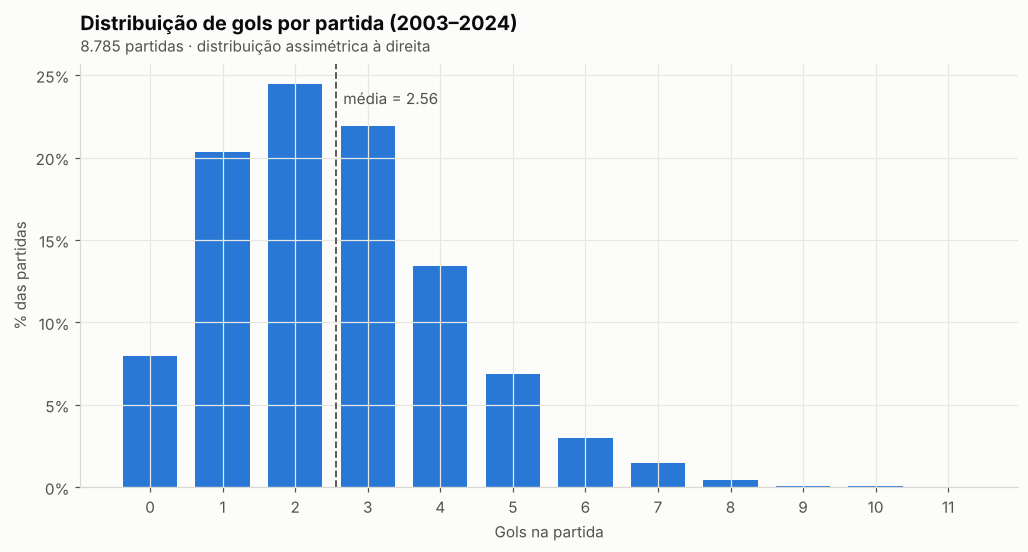

In [24]:
fig, ax = plt.subplots()
contagem = partidas.total_gols.value_counts(normalize=True).sort_index()
ax.bar(contagem.index, contagem.values, color=AZUL, width=0.75)
media = partidas.total_gols.mean()
ax.axvline(media, color=TEXTO_2, ls="--", lw=1.2)
ax.text(media + 0.1, contagem.max() * 0.95, f"média = {media:.2f}", color=TEXTO_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xticks(contagem.index)
ax.set_xlabel("Gols na partida"); ax.set_ylabel("% das partidas")
ax.set_title("Distribuição de gols por partida (2003–2024)", pad=22)
subtitulo(ax, f"{len(partidas):,} partidas · distribuição assimétrica à direita".replace(",", "."))
plt.show()

In [25]:
# Placares mais frequentes (do ponto de vista do mandante)
placares = (partidas.mandante_placar.astype(str) + " x " + partidas.visitante_placar.astype(str)).value_counts()
(placares.head(10) / len(partidas)).to_frame("% das partidas").style.format("{:.1%}")

,% das partidas
1 x 0,13.2%
1 x 1,12.4%
2 x 1,9.8%
2 x 0,8.4%
0 x 0,7.9%
0 x 1,7.2%
1 x 2,6.2%
2 x 2,5.2%
3 x 0,4.5%
3 x 1,4.4%


### Análise 2 — Tendência por temporada: gols e resultados

In [26]:
tendencia = partidas.groupby("temporada").agg(
    partidas=("partida_id", "size"),
    media_gols=("total_gols", "mean"),
    vit_mandante=("resultado", lambda s: (s == "Vitória mandante").mean()),
    empate=("resultado", lambda s: (s == "Empate").mean()),
    vit_visitante=("resultado", lambda s: (s == "Vitória visitante").mean()),
)
tendencia.style.format({"media_gols": "{:.2f}", "vit_mandante": "{:.1%}", "empate": "{:.1%}", "vit_visitante": "{:.1%}"}) \
         .background_gradient(subset=["vit_mandante"], cmap="Blues")

,partidas,media_gols,vit_mandante,empate,vit_visitante
temporada,,,,,
2003,552,2.89,53.8%,25.7%,20.5%
2004,552,2.78,52.2%,25.4%,22.5%
2005,462,3.13,50.9%,22.1%,27.1%
2006,380,2.71,50.3%,25.5%,24.2%
2007,380,2.76,50.5%,23.7%,25.8%
2008,380,2.72,54.7%,25.3%,20.0%
2009,380,2.88,51.3%,26.8%,21.8%
2010,380,2.57,47.1%,31.1%,21.8%
2011,380,2.68,48.4%,27.6%,23.9%


In [27]:
# Comparação por período
periodos = pd.cut(partidas.temporada, bins=[2002, 2009, 2019, 2020, 2024],
                  labels=["2003–2009", "2010–2019", "2020 (sem público)", "2021–2024"])
por_periodo = partidas.groupby(periodos, observed=True).agg(
    partidas=("partida_id", "size"), media_gols=("total_gols", "mean"),
    vit_mandante=("resultado", lambda s: (s == "Vitória mandante").mean()),
    empate=("resultado", lambda s: (s == "Empate").mean()),
    vit_visitante=("resultado", lambda s: (s == "Vitória visitante").mean()),
)
por_periodo.style.format({"media_gols": "{:.2f}", "vit_mandante": "{:.1%}", "empate": "{:.1%}", "vit_visitante": "{:.1%}"})

,partidas,media_gols,vit_mandante,empate,vit_visitante
temporada,,,,,
2003–2009,3086,2.85,52.0%,24.9%,23.0%
2010–2019,3799,2.41,49.5%,27.0%,23.5%
2020 (sem público),380,2.48,45.0%,28.4%,26.6%
2021–2024,1520,2.38,46.1%,27.6%,26.3%


### Análise 3 — Fator casa por clube (aproveitamento em casa × fora)

In [28]:
# Aproveitamento geral de todos os clubes em casa e fora
geral = jogos_clube.groupby("mando").pontos.agg(lambda s: s.sum() / (len(s) * 3))
print(f"Aproveitamento geral — em casa: {geral['Casa']:.1%} | fora: {geral['Fora']:.1%}")

# Apenas clubes com pelo menos 10 temporadas na Série A, para comparar amostras grandes
temporadas_clube = jogos_clube.groupby("clube").temporada.nunique()
clubes_frequentes = temporadas_clube[temporadas_clube >= 10].index

aprov = (jogos_clube[jogos_clube.clube.isin(clubes_frequentes)]
         .groupby(["clube", "mando"]).pontos.agg(lambda s: s.sum() / (len(s) * 3))
         .unstack())
aprov["diferenca_pp"] = (aprov.Casa - aprov.Fora) * 100
aprov["temporadas"] = temporadas_clube
aprov = aprov.sort_values("diferenca_pp", ascending=False)
aprov.style.format({"Casa": "{:.1%}", "Fora": "{:.1%}", "diferenca_pp": "{:+.1f} p.p."})

Aproveitamento geral — em casa: 58.4% | fora: 32.8%


mando,Casa,Fora,diferenca_pp,temporadas
clube,,,,
Athletico-PR,64.4%,30.0%,+34.4 p.p.,21
Sport,55.7%,24.1%,+31.6 p.p.,11
Gremio,66.0%,35.2%,+30.8 p.p.,20
Coritiba,55.7%,25.4%,+30.3 p.p.,15
Santos,64.9%,35.9%,+28.9 p.p.,21
Internacional,66.7%,38.0%,+28.7 p.p.,21
Vitoria,52.4%,26.7%,+25.7 p.p.,11
Goias,56.3%,30.6%,+25.6 p.p.,15
Sao Paulo,66.4%,41.4%,+25.0 p.p.,22


### Análise 4 — Outliers: goleadas e jogos fora do padrão (método IQR)

In [29]:
q1, q3 = partidas.total_gols.quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
outliers = partidas[partidas.total_gols > limite]
print(f"Q1 = {q1:.0f} | Q3 = {q3:.0f} | limite superior (Q3 + 1,5·IQR) = {limite:.1f}")
print(f"Partidas outliers (mais de {limite:.0f} gols): {len(outliers)} ({len(outliers) / len(partidas):.1%})")
outliers.nlargest(8, "total_gols")[["temporada", "data", "mandante", "mandante_placar", "visitante_placar", "visitante", "total_gols"]]

Q1 = 1 | Q3 = 4 | limite superior (Q3 + 1,5·IQR) = 8.5
Partidas outliers (mais de 8 gols): 13 (0.1%)


,temporada,data,mandante,mandante_placar,visitante_placar,visitante,total_gols
450,2003,2003-10-22,Bahia,4,7,Santos,11
23,2003,2003-04-06,Vasco,6,4,Goias,10
1876,2006,2006-11-01,Athletico-PR,6,4,Vasco,10
2333,2008,2008-05-11,Portuguesa,5,5,Figueirense,10
8275,2023,2023-10-07,Goias,4,6,Bahia,10
616,2004,2004-05-16,Criciuma,7,2,Goias,9
1258,2005,2005-07-27,Athletico-PR,7,2,Vasco,9
1286,2005,2005-08-06,Athletico-PR,5,4,Cruzeiro,9


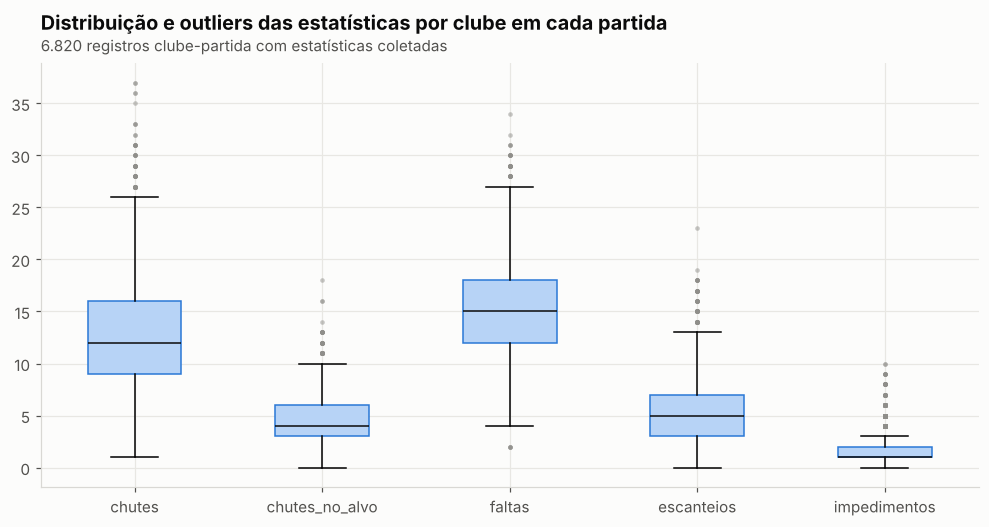

,temporada,data,clube,adversario,chutes,chutes_no_alvo,gols_pro,resultado_clube
15076,2021,2021-10-25,Palmeiras,Sport,37.00,16.00,2,Vitória
15591,2022,2022-07-09,Bragantino,Avai,37.00,13.00,4,Vitória
16036,2022,2022-11-13,America-MG,Atletico-GO,36.00,9.00,1,Empate
16269,2023,2023-06-22,Bragantino,Flamengo,36.00,13.00,4,Vitória
15578,2022,2022-07-02,Palmeiras,Athletico-PR,35.00,7.00,0,Derrota


In [30]:
# Outliers nas estatísticas de jogo (boxplots das métricas por clube/partida)
met = ["chutes", "chutes_no_alvo", "faltas", "escanteios", "impedimentos"]
disp = estatisticas[estatisticas.stats_disponivel]
fig, ax = plt.subplots()
bp = ax.boxplot([disp[m].dropna() for m in met], tick_labels=met, patch_artist=True, widths=0.5,
                medianprops=dict(color=TEXTO), flierprops=dict(marker="o", markersize=3, markerfacecolor=CINZA, markeredgecolor="none", alpha=0.5))
for caixa in bp["boxes"]:
    caixa.set_facecolor("#b7d3f6"); caixa.set_edgecolor(AZUL)
ax.set_title("Distribuição e outliers das estatísticas por clube em cada partida", pad=22)
subtitulo(ax, f"{len(disp):,} registros clube-partida com estatísticas coletadas".replace(",", "."))
plt.show()

extremos = disp.nlargest(5, "chutes")[["temporada", "data", "clube", "adversario", "chutes", "chutes_no_alvo", "gols_pro", "resultado_clube"]]
extremos

### Análise 5 — Correlação entre estatísticas de jogo, gols e pontos

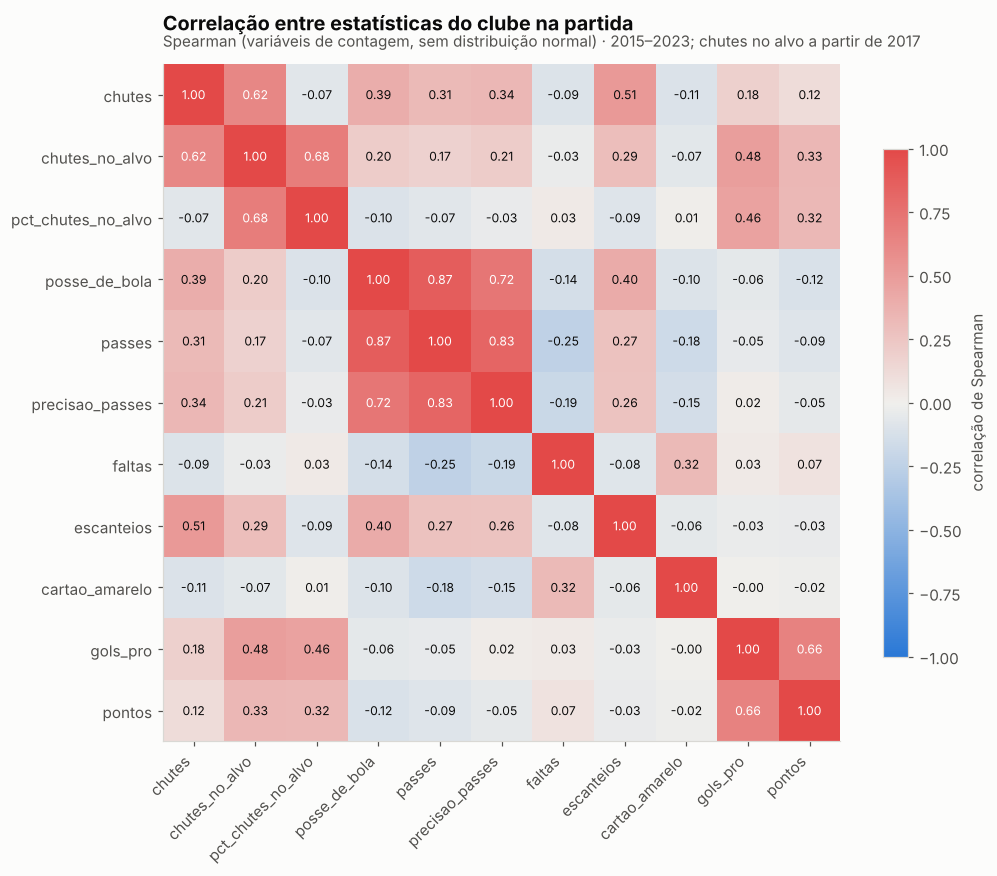

In [31]:
cols_corr = ["chutes", "chutes_no_alvo", "pct_chutes_no_alvo", "posse_de_bola", "passes", "precisao_passes",
             "faltas", "escanteios", "cartao_amarelo", "gols_pro", "pontos"]
corr = disp[cols_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap=DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_corr)), cols_corr, rotation=45, ha="right")
ax.set_yticks(range(len(cols_corr)), cols_corr)
ax.grid(False)
for i in range(len(cols_corr)):
    for j in range(len(cols_corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else TEXTO)
fig.colorbar(im, ax=ax, shrink=0.75, label="correlação de Spearman")
ax.set_title("Correlação entre estatísticas do clube na partida", pad=22)
subtitulo(ax, "Spearman (variáveis de contagem, sem distribuição normal) · 2015–2023; chutes no alvo a partir de 2017")
plt.show()

In [32]:
corr[["gols_pro", "pontos"]].drop(["gols_pro", "pontos"]).sort_values("gols_pro", ascending=False) \
    .style.format("{:+.2f}").background_gradient(cmap=DIVERGENTE, vmin=-1, vmax=1)

,gols_pro,pontos
chutes_no_alvo,+0.48,+0.33
pct_chutes_no_alvo,+0.46,+0.32
chutes,+0.18,+0.12
faltas,+0.03,+0.07
precisao_passes,+0.02,-0.05
cartao_amarelo,-0.00,-0.02
escanteios,-0.03,-0.03
passes,-0.05,-0.09
posse_de_bola,-0.06,-0.12


### Análise 6 — Dispersão: chutes no alvo × gols marcados

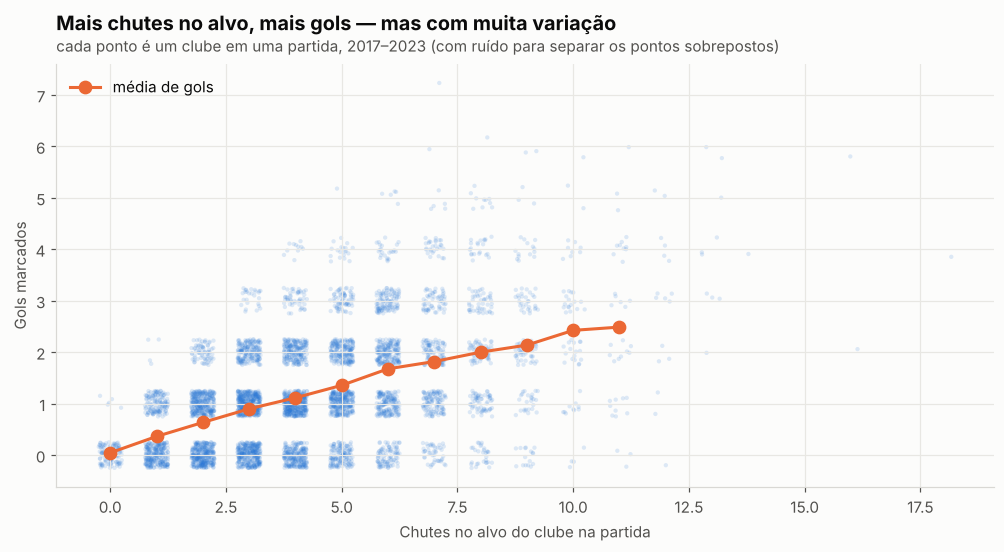

In [33]:
rng = np.random.default_rng(42)
fig, ax = plt.subplots()
x = disp.chutes_no_alvo + rng.uniform(-0.25, 0.25, len(disp))
y = disp.gols_pro + rng.uniform(-0.25, 0.25, len(disp))
ax.scatter(x, y, s=8, alpha=0.15, color=AZUL, edgecolors="none")
medias = disp.groupby("chutes_no_alvo").gols_pro.mean()
medias = medias[disp.chutes_no_alvo.value_counts().reindex(medias.index) >= 30]
ax.plot(medias.index, medias.values, color=LARANJA, marker="o", markersize=8, label="média de gols")
ax.set_xlabel("Chutes no alvo do clube na partida"); ax.set_ylabel("Gols marcados")
ax.legend(loc="upper left")
ax.set_title("Mais chutes no alvo, mais gols — mas com muita variação", pad=22)
subtitulo(ax, "cada ponto é um clube em uma partida, 2017–2023 (com ruído para separar os pontos sobrepostos)")
plt.show()

In [34]:
# Taxa de conversão: quantos chutes no alvo são necessários por gol?
# Só as linhas em que chutes no alvo foi coletado (2017+), senão somaríamos gols sem os chutes correspondentes
com_alvo = disp.dropna(subset=["chutes_no_alvo"])
conv = com_alvo.gols_pro.sum() / com_alvo.chutes_no_alvo.sum()
print(f"Gols por chute no alvo: {conv:.1%}  →  ~{1 / conv:.1f} chutes no alvo por gol")
print(f"Gols por chute (total): {disp.gols_pro.sum() / disp.chutes.sum():.1%}")

Gols por chute no alvo: 27.5%  →  ~3.6 chutes no alvo por gol
Gols por chute (total): 9.2%


### Análise 7 — Posse de bola vence jogo?

In [35]:
posse = disp.dropna(subset=["faixa_posse"]).groupby("faixa_posse", observed=True).agg(
    registros=("pontos", "size"),
    pct_vitoria=("resultado_clube", lambda s: (s == "Vitória").mean()),
    media_gols=("gols_pro", "mean"),
    media_chutes=("chutes", "mean"),
)
posse.style.format({"pct_vitoria": "{:.1%}", "media_gols": "{:.2f}", "media_chutes": "{:.1f}"})

,registros,pct_vitoria,media_gols,media_chutes
faixa_posse,,,,
Até 40%,1207,42.8%,1.24,10.1
40–45%,988,41.1%,1.17,11.4
45–50%,1206,38.2%,1.21,12.3
50–55%,1005,37.2%,1.25,13.2
55–60%,1031,31.6%,1.12,14.0
Acima de 60%,1383,29.6%,1.11,15.9


In [36]:
# Posse × resultado separado por mando: o efeito muda quando o clube joga em casa?
pd.crosstab(disp.faixa_posse, disp.mando, values=(disp.resultado_clube == "Vitória"), aggfunc="mean") \
  .style.format("{:.1%}")

mando,Casa,Fora
faixa_posse,,
Até 40%,59.8%,32.6%
40–45%,55.6%,29.4%
45–50%,53.8%,24.9%
50–55%,50.5%,22.4%
55–60%,42.0%,18.4%
Acima de 60%,38.0%,16.3%


### Análise 8 — Quando saem os gols e os cartões

In [37]:
ordem = ["0–15", "16–30", "31–45", "45+ (acréscimos)", "46–60", "61–75", "76–90", "90+ (acréscimos)"]
minutos = pd.DataFrame({
    "% dos gols": gols.faixa_minuto.value_counts(normalize=True),
    "% dos cartões amarelos": cartoes[cartoes.cartao == "Amarelo"].faixa_minuto.value_counts(normalize=True),
    "% dos cartões vermelhos": cartoes[cartoes.cartao == "Vermelho"].faixa_minuto.value_counts(normalize=True),
}).reindex(ordem)
minutos.style.format("{:.1%}")

,% dos gols,% dos cartões amarelos,% dos cartões vermelhos
faixa_minuto,,,
0–15,12.2%,5.1%,2.3%
16–30,13.5%,10.8%,4.5%
31–45,15.2%,16.0%,8.1%
45+ (acréscimos),3.5%,4.1%,3.5%
46–60,15.7%,14.1%,11.0%
61–75,16.5%,17.9%,18.0%
76–90,16.6%,21.5%,25.9%
90+ (acréscimos),6.9%,10.4%,26.7%


In [38]:
print(f"Gols no 2º tempo: {(gols.tempo == '2º tempo').mean():.1%}")
print(f"Gols nos acréscimos (45+ e 90+): {gols.acrescimo.mean():.1%}")
print(f"Pênaltis: {(gols.tipo_de_gol == 'Pênalti').mean():.1%} dos gols | Gols contra: {(gols.tipo_de_gol == 'Gol Contra').mean():.1%}")
print(f"Gols do mandante: {(gols.mando == 'Casa').mean():.1%}")

Gols no 2º tempo: 55.7%
Gols nos acréscimos (45+ e 90+): 10.4%
Pênaltis: 9.5% dos gols | Gols contra: 2.5%
Gols do mandante: 59.5%


In [39]:
# Os acréscimos estão ficando mais longos? % dos gols e dos cartões marcados nos acréscimos do 2º tempo (90+)
acresc = pd.DataFrame({
    "% gols no 90+": gols.groupby("temporada").faixa_minuto.apply(lambda s: (s == "90+ (acréscimos)").mean()),
    "% cartões no 90+": cartoes.groupby("temporada").faixa_minuto.apply(lambda s: (s == "90+ (acréscimos)").mean()),
    "maior minuto registrado": gols.groupby("temporada").minuto_num.max(),
})
acresc.style.format({"% gols no 90+": "{:.1%}", "% cartões no 90+": "{:.1%}"})

,% gols no 90+,% cartões no 90+,maior minuto registrado
temporada,,,
2014,5.1%,7.6%,95
2015,5.4%,9.1%,98
2016,4.5%,7.8%,103
2017,6.2%,8.7%,98
2018,6.4%,9.9%,102
2019,7.3%,11.3%,101
2020,8.4%,12.7%,101
2021,8.3%,13.3%,100
2022,7.6%,11.6%,103


In [40]:
# Cartões por posição (em relação ao total de cartões de cada cor)
pd.crosstab(cartoes.posicao, cartoes.cartao, normalize="columns").sort_values("Amarelo", ascending=False).style.format("{:.1%}")

cartao,Amarelo,Vermelho
posicao,,
Meio-campo,41.8%,35.5%
Zagueiro,35.4%,41.3%
Atacante,13.7%,13.8%
Não informado,5.7%,6.1%
Goleiro,3.4%,3.3%


### Principais insights da análise exploratória

1. **Gols:** uma partida tem em média **2,56 gols** (mediana e moda = 2). Os placares mais comuns são **1 x 0 (13,2%)** e **1 x 1 (12,4%)**; o 0 x 0 aparece em 7,9% dos jogos.
2. **O campeonato ficou com menos gols:** a média caiu de **2,85 gols por jogo em 2003–2009** para **2,41 em 2010–2019** e **2,38 em 2021–2024**.
3. **O fator casa existe, mas está encolhendo:** o mandante venceu **52,0%** dos jogos em 2003–2009, **49,5%** em 2010–2019 e **46,1%** em 2021–2024, enquanto as vitórias do visitante subiram de 23,0% para 26,3%.
4. **2020 sem público:** o mandante venceu 45,0% dos jogos, abaixo de todos os períodos com torcida. Mas a queda começou antes (2017 já teve 43,9%) e não voltou ao patamar antigo com a volta do público, então a torcida não explica sozinha a tendência.
5. **Todos os clubes rendem mais em casa:** o aproveitamento geral é de **58,4% em casa contra 32,8% fora**. Entre os 19 clubes com 10+ temporadas, a diferença vai de +20,7 p.p. (Botafogo) a **+34,4 p.p. (Athletico-PR)**.
6. **Outliers:** pelo critério do IQR, só 13 partidas (0,1%) tiveram 9 gols ou mais; a maior foi **Bahia 4 x 7 Santos (2003)**.
7. **Finalizar no gol importa mais que ter a bola:** chutes no alvo têm a maior correlação com gols (**+0,48**) e pontos (+0,33). Posse de bola (−0,06) e passes (−0,05) praticamente não se relacionam com gols. São necessários **~3,6 chutes no alvo por gol**.
8. **O paradoxo da posse:** clubes com até 40% de posse venceram **42,8%** dos jogos; com mais de 60%, só **29,6%**. Correlação não é causalidade: o time que sai na frente costuma recuar e ceder a bola, e equipes de contra-ataque vencem com pouca posse.
9. **O fim do jogo decide:** **55,7%** dos gols saem no 2º tempo e a faixa 76–90 + acréscimos concentra **52,6%** dos cartões vermelhos. A fatia de gols nos acréscimos do 2º tempo subiu de **5,1% (2014)** para **8–9% (2020–2024)**, sinal de acréscimos mais longos.
10. **Qualidade dos dados:** estatísticas de jogo só existem de 2015 a 2023 (chutes no alvo a partir de 2017; precisão de passe a partir de 2018), e gols e cartões a partir de 2014. Sem esse diagnóstico, os zeros não coletados teriam distorcido todas as médias.

---
# Fase 4 — Visualização de dados

Seis visualizações finais que contam a história da análise. O dashboard interativo está no Looker Studio (link no relatório),
alimentado pelos CSVs exportados ao final deste notebook.

### Visualização 1 — Gráfico de linha: o fator casa ao longo de 22 temporadas

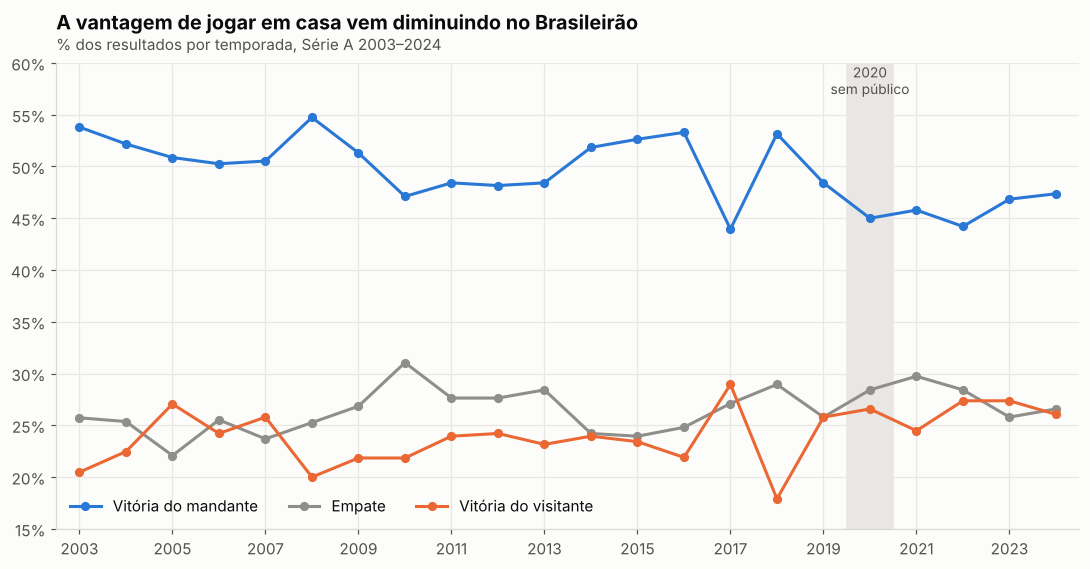

In [41]:
fig, ax = plt.subplots(figsize=(12, 5.5))
series = [("vit_mandante", "Vitória do mandante", AZUL), ("empate", "Empate", CINZA), ("vit_visitante", "Vitória do visitante", LARANJA)]
for col, nome, cor in series:
    ax.plot(tendencia.index, tendencia[col], color=cor, marker="o", markersize=5, label=nome)
ax.axvspan(2019.5, 2020.5, color="#e8e7e3", zorder=0)
ax.text(2020, 0.57, "2020\nsem público", ha="center", color=TEXTO_2, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xticks(tendencia.index[::2])
ax.set_xlim(2002.5, 2024.5); ax.set_ylim(0.15, 0.6)
ax.legend(loc="lower left", ncols=3)
ax.set_title("A vantagem de jogar em casa vem diminuindo no Brasileirão", pad=22)
subtitulo(ax, "% dos resultados por temporada, Série A 2003–2024")
plt.show()

### Visualização 2 — Gráfico de barras: aproveitamento em casa × fora dos clubes

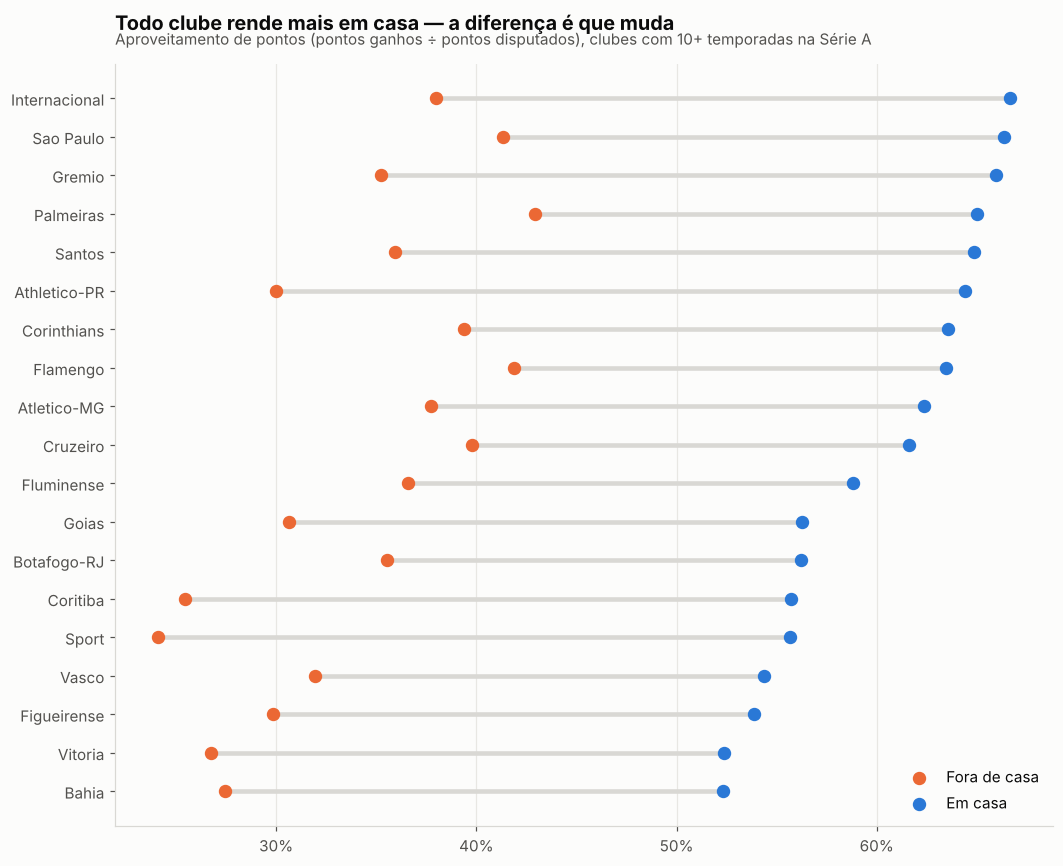

In [42]:
top = aprov.sort_values("Casa")
fig, ax = plt.subplots(figsize=(11, 9))
y = np.arange(len(top))
ax.hlines(y, top.Fora, top.Casa, color="#d9d8d4", lw=3)
ax.scatter(top.Fora, y, color=LARANJA, s=60, zorder=3, label="Fora de casa")
ax.scatter(top.Casa, y, color=AZUL, s=60, zorder=3, label="Em casa")
ax.set_yticks(y, top.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title("Todo clube rende mais em casa — a diferença é que muda", pad=22)
subtitulo(ax, "Aproveitamento de pontos (pontos ganhos ÷ pontos disputados), clubes com 10+ temporadas na Série A")
plt.show()

### Visualização 3 — Barras: em que minuto saem os gols

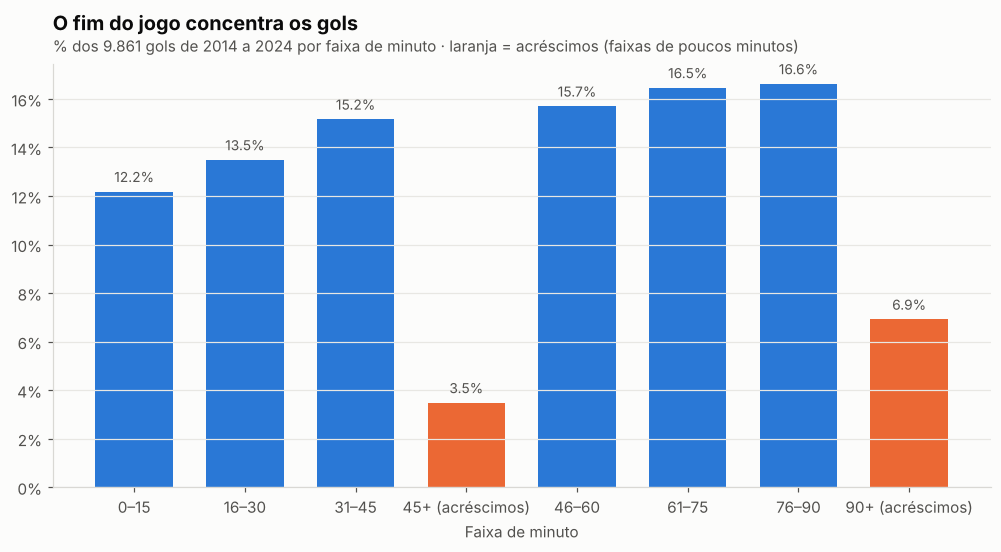

In [43]:
fig, ax = plt.subplots()
cores = [AZUL if "acréscimos" not in f else LARANJA for f in ordem]
ax.bar(ordem, minutos["% dos gols"], color=cores, width=0.7)
for i, v in enumerate(minutos["% dos gols"]):
    ax.text(i, v + 0.004, f"{v:.1%}", ha="center", fontsize=9, color=TEXTO_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Faixa de minuto"); ax.grid(axis="x", visible=False)
ax.set_title("O fim do jogo concentra os gols", pad=22)
subtitulo(ax, f"% dos {len(gols):,} gols de 2014 a 2024 por faixa de minuto · laranja = acréscimos (faixas de poucos minutos)".replace(",", "."))
plt.show()

### Visualização 4 — Dispersão: finalização × resultado por clube e temporada

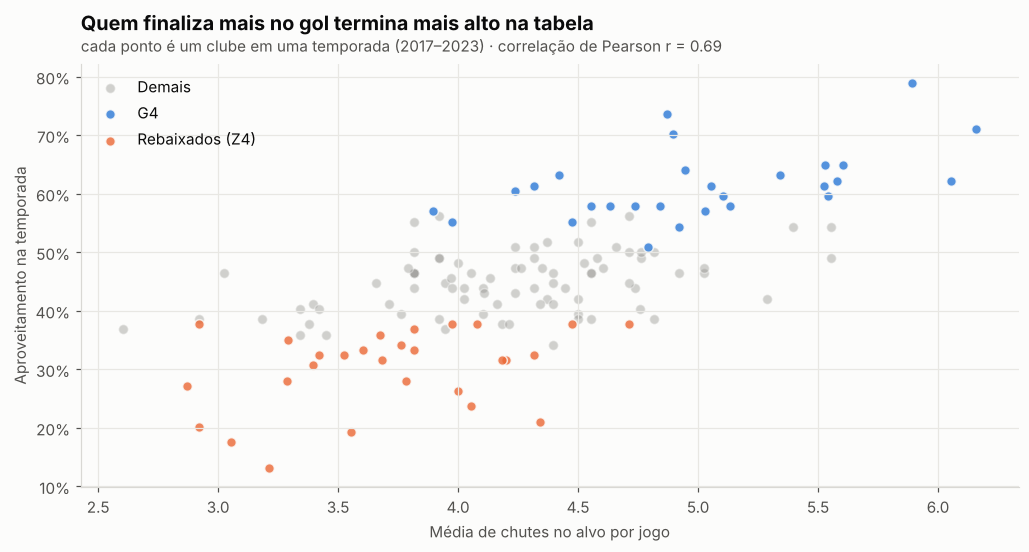

In [44]:
agg_ct = (disp.groupby(["temporada", "clube"])
          .agg(chutes_alvo=("chutes_no_alvo", "mean"), pontos=("pontos", "sum"), jogos=("pontos", "size"))
          .reset_index())
agg_ct = agg_ct[(agg_ct.jogos >= 30) & agg_ct.chutes_alvo.notna()].merge(classificacao[["temporada", "clube", "posicao", "aproveitamento"]], on=["temporada", "clube"])
agg_ct["grupo"] = np.select([agg_ct.posicao <= 4, agg_ct.posicao >= 17], ["G4", "Rebaixados (Z4)"], default="Demais")

fig, ax = plt.subplots()
for grupo, cor in [("Demais", CINZA), ("G4", AZUL), ("Rebaixados (Z4)", LARANJA)]:
    d = agg_ct[agg_ct.grupo == grupo]
    ax.scatter(d.chutes_alvo, d.aproveitamento, s=40, color=cor, alpha=0.8 if grupo != "Demais" else 0.4,
               edgecolors="#fcfcfb", linewidths=1, label=grupo)
r = agg_ct[["chutes_alvo", "aproveitamento"]].corr().iloc[0, 1]
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Média de chutes no alvo por jogo"); ax.set_ylabel("Aproveitamento na temporada")
ax.legend(loc="upper left")
ax.set_title("Quem finaliza mais no gol termina mais alto na tabela", pad=22)
subtitulo(ax, f"cada ponto é um clube em uma temporada (2017–2023) · correlação de Pearson r = {r:.2f}")
plt.show()

### Visualização 5 — Mapa de calor: gols e cartões ao longo da partida, temporada a temporada

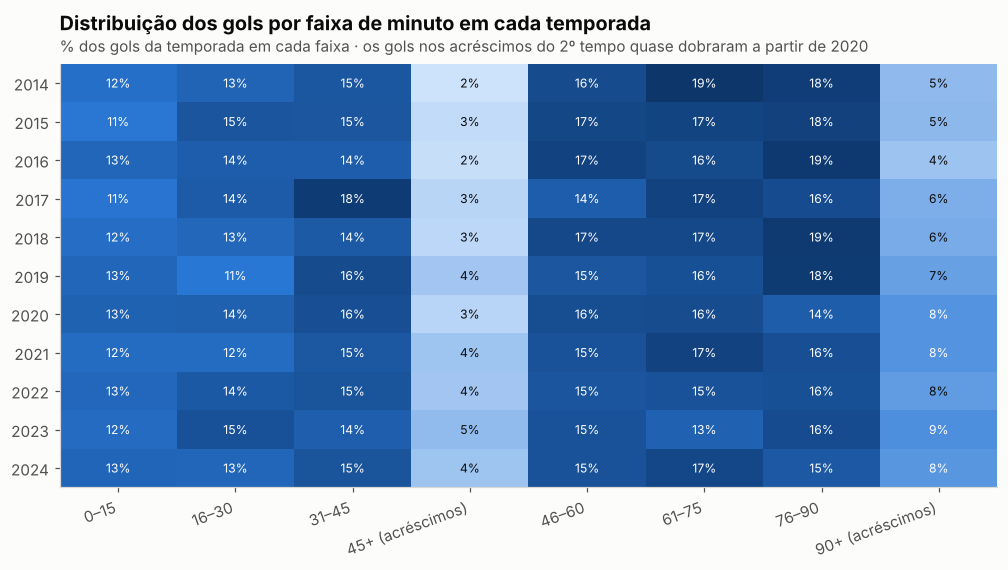

In [45]:
mapa = pd.crosstab(gols.temporada, gols.faixa_minuto, normalize="index")[ordem]
fig, ax = plt.subplots(figsize=(11, 5))
azuis = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#2a78d6", "#0d366b"])
im = ax.imshow(mapa, cmap=azuis, aspect="auto")
ax.set_xticks(range(len(ordem)), ordem, rotation=20, ha="right")
ax.set_yticks(range(len(mapa)), mapa.index)
ax.grid(False)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.iloc[i, j]
        escuro = (v - mapa.values.min()) / (mapa.values.max() - mapa.values.min()) > 0.35
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if escuro else TEXTO)
ax.set_title("Distribuição dos gols por faixa de minuto em cada temporada", pad=22)
subtitulo(ax, "% dos gols da temporada em cada faixa · os gols nos acréscimos do 2º tempo quase dobraram a partir de 2020")
plt.show()

### Visualização 6 — Tabela dinâmica: campeões e pontuação por temporada

In [46]:
pivot = classificacao[classificacao.posicao <= 4].pivot_table(
    index="temporada", columns="posicao", values=["clube", "pontos"], aggfunc="first")
tabela = pd.DataFrame({
    "Campeão": pivot["clube"][1], "Pts campeão": pivot["pontos"][1],
    "Vice": pivot["clube"][2], "Pts vice": pivot["pontos"][2],
    "Diferença": pivot["pontos"][1] - pivot["pontos"][2],
    "4º colocado": pivot["clube"][4],
})
tabela.style.background_gradient(subset=["Diferença"], cmap="Blues").format(precision=0)

,Campeão,Pts campeão,Vice,Pts vice,Diferença,4º colocado
temporada,,,,,,
2003,Cruzeiro,100,Santos,87,13,Coritiba
2004,Santos,89,Athletico-PR,86,3,Palmeiras
2005,Corinthians,81,Internacional,78,3,Palmeiras
2006,Sao Paulo,78,Internacional,69,9,Santos
2007,Sao Paulo,77,Santos,62,15,Fluminense
2008,Sao Paulo,75,Gremio,72,3,Palmeiras
2009,Flamengo,67,Internacional,65,2,Cruzeiro
2010,Fluminense,71,Cruzeiro,69,2,Gremio
2011,Corinthians,71,Vasco,69,2,Flamengo


In [47]:
titulos = campeoes.clube.value_counts().to_frame("títulos 2003–2024")
titulos

,títulos 2003–2024
clube,
Corinthians,4
Palmeiras,4
Cruzeiro,3
Sao Paulo,3
Flamengo,3
Fluminense,2
Santos,1
Atletico-MG,1
Botafogo-RJ,1


---
# Exportação para o Looker Studio

As tabelas tratadas são salvas em CSV (UTF-8, separador vírgula, datas em `AAAA-MM-DD`) na pasta `dados_tratados/`.
Cada arquivo vira uma fonte de dados no Looker Studio; `jogos_clube` é a principal do dashboard.

In [48]:
SAIDA = Path("dados_tratados")
SAIDA.mkdir(exist_ok=True)

exportar = {
    "partidas": partidas,
    "jogos_clube": jogos_clube,
    "classificacao": classificacao,
    "estatisticas": estatisticas[estatisticas.stats_disponivel].drop(columns="stats_disponivel"),
    "gols": gols,
    "cartoes": cartoes,
}
for nome, df in exportar.items():
    df.to_csv(SAIDA / f"{nome}.csv", index=False, date_format="%Y-%m-%d", float_format="%.4f")
    print(f"{nome + '.csv':20s} {len(df):>7,} linhas × {df.shape[1]:>2} colunas")

partidas.csv           8,785 linhas × 28 colunas
jogos_clube.csv       17,570 linhas × 16 colunas
classificacao.csv        450 linhas ×  9 colunas
estatisticas.csv       6,820 linhas × 23 colunas
gols.csv               9,861 linhas × 15 colunas


cartoes.csv           20,953 linhas × 17 colunas


---
# Conclusões

**1. A vantagem de jogar em casa é real e grande, mas está diminuindo.** Em casa os clubes conquistam 58,4% dos pontos; fora, 32,8%. Só que a vitória do mandante caiu de 52,0% (2003–2009) para 46,1% (2021–2024).

**2. A temporada sem público (2020) reforça o papel da torcida, mas não explica tudo.** O mandante venceu 45,0% dos jogos em 2020, o menor nível dos períodos analisados, porém a queda já vinha antes e não se reverteu com a volta do público. Hipóteses para investigar: mais equilíbrio técnico entre os clubes, gramados e logística de viagem melhores e o uso do VAR (a partir de 2019).

**3. Para ganhar, finalizar no gol vale mais que ter a bola.** Chutes no alvo são a estatística mais ligada a gols (Spearman +0,48) e, somando a temporada, a média de chutes no alvo responde por cerca de metade da variação do aproveitamento (r = 0,69; r² ≈ 0,48). Ter mais posse não se traduz em vitória.

**4. O jogo se decide no fim.** O 2º tempo concentra 55,7% dos gols, e os acréscimos ficaram mais longos: a fatia de gols após os 90 minutos quase dobrou desde 2014.

**Limitações:** as estatísticas de jogo cobrem apenas 2015–2023, a base não traz público presente nem punições do STJD, e as relações encontradas são correlações, não causas.

**Próximos passos:** cruzar com dados de público por partida (CBF) e de valor de elenco para testar as hipóteses do fator casa.